In [1]:
import locan as lc
import pandas as pd
import numpy as np
import napari
import matplotlib.pyplot as plt

In [2]:
loc_file_640 = r"F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\results_decode\250714_Ofa-647_C1q-568_WGA-405_3_dSTORM_640_combined_fit-250704_drift_aligned.asdf"
locs_640 = lc.load_asdf_file(loc_file_640)
loc_file_532 = r"F:\B-cell_CD20-RTX\250708_therpeutical_ABs_whole_cell_DI-matched\results_decode\250714_Ofa-647_C1q-568_WGA-405_3_dSTORM_532_stack_combined_fit-250709_drift_aligned.asdf"
locs_532 = lc.load_asdf_file(loc_file_532)

In [3]:
locs_640.data.describe()

,local_background,frame,original_index,intensity,phot_sig,prob,position_x,position_y,position_z,x_sig,y_sig,z_sig
count,186562.000000,186562.000000,186562.0,186562.000000,186562.000000,186562.000000,186562.000000,186562.000000,186562.000000,186562.000000,186562.000000,186562.000000
mean,65.551178,38469.294626,-1.0,6574.905762,646.665306,0.467635,15374.848633,15529.132812,10400.300781,13.267252,13.181260,30.102064
std,6.917309,28734.338745,0.0,3088.792725,372.783475,0.084043,4017.361084,3981.398926,2618.658691,3.384194,3.761248,8.051722
min,30.351854,0.000000,-1.0,455.746399,171.738754,0.300001,1790.983276,1421.196655,3926.479492,2.907435,2.883897,7.381460
25%,60.881380,13283.250000,-1.0,4604.183472,411.985229,0.415724,12047.347900,12144.968262,8756.084717,10.759903,10.325512,23.827493
50%,64.788185,30596.000000,-1.0,6320.587402,535.865631,0.463408,16121.994629,16086.379395,10772.522949,13.109357,12.844027,30.157734
75%,69.515968,57549.500000,-1.0,8182.755371,765.366837,0.509090,19009.872559,19163.670898,12255.802002,15.661099,15.911740,36.603255
max,146.698761,104991.000000,-1.0,22761.593750,6029.586914,0.998795,28415.376953,28313.794922,16454.316406,21.998987,21.999985,44.999218


In [4]:
viewer = napari.Viewer(ndisplay=3)

In [5]:
test = lc.select_by_condition(locs_640, condition=f'0 < position_z < 105_000')
prob_width = 25  # range of point size

coordinates = pd.DataFrame(
    {
        'position_z': test.data.position_z,
        'position_x': test.data.position_x,
        'position_y': test.data.position_y,

    })

colors = test.data.frame.to_numpy()
colors_norm = (colors - np.min(colors)) / (np.max(colors) - np.min(colors))

#prob = dat_640_xyz_cor.data.localization_count.to_numpy()#*111
#prob_norm = (prob - prob.min())/np.ptp(prob) * prob_width + 1
prob = test.data.x_sig.to_numpy()
prob_norm = (prob - prob.min())/np.ptp(prob) * prob_width + 1

point_features = {
    'z_value': colors_norm,
    'prob': (1/prob).tolist(),
}

points = coordinates.to_numpy()

viewer.add_points(points, symbol='o', features=point_features, face_color='#280028', face_colormap= '#280028', border_color='#280028', border_colormap='#280028', size=prob_width, name='640 offset corrected', blending='additive')

<Points layer '640 offset corrected' at 0x2056f807620>

In [6]:
test = lc.select_by_condition(locs_532, condition=f'0 < position_z < 105_000')
prob_width = 25  # range of point size

coordinates = pd.DataFrame(
    {
        'position_z': test.data.position_z,
        'position_x': test.data.position_x,
        'position_y': test.data.position_y,

    })

colors = test.data.frame.to_numpy()
colors_norm = (colors - np.min(colors)) / (np.max(colors) - np.min(colors))


prob = 1/test.data.x_sig.to_numpy()
prob_norm = (prob - prob.min())/np.ptp(prob) * prob_width + 1
x_sig = test.data.x_sig.to_numpy()

point_features = {
    'z_value': colors_norm,
    'prob': (prob_norm).tolist(),
    'x_sig': x_sig,
}

points = coordinates.to_numpy()

viewer.add_points(points, symbol='o', features=point_features, face_color='green', face_colormap= 'green', border_color='green', border_colormap='green', size=prob_width, name='532 offset corrected', blending='additive')

<Points layer '532 offset corrected' at 0x20568b34910>

In [7]:
test = lc.select_by_condition(locs_640, condition=f'0 < position_z < 105_000')
prob_width = 10  # range of point size

coordinates = pd.DataFrame(
    {
        'position_z': test.data.position_z,
        'position_x': test.data.position_x,
        'position_y': test.data.position_y,

    })

colors = test.data.position_z.to_numpy()
colors_norm = (colors - np.min(colors)) / (np.max(colors) - np.min(colors))

#prob = dat_640_xyz_cor.data.localization_count.to_numpy()#*111
#prob_norm = (prob - prob.min())/np.ptp(prob) * prob_width + 1
prob = test.data.x_sig.to_numpy()
prob_norm = (prob - prob.min())/np.ptp(prob) * prob_width + 1

point_features = {
    'z_value': colors_norm,
    'prob': (1/prob).tolist(),
}

points = coordinates.to_numpy()

viewer.add_points(points, symbol='o', features=point_features, face_color='z_value', face_colormap= 'jet', border_color='z_value', border_colormap='jet', size=prob_width, name='640 offset corrected', blending='additive', opacity=0.5)

<Points layer '640 offset corrected [1]' at 0x2057785b750>

In [8]:
test = lc.select_by_condition(locs_532, condition=f'0 < position_z < 105_000')
prob_width = 10  # range of point size

coordinates = pd.DataFrame(
    {
        'position_z': test.data.position_z,
        'position_x': test.data.position_x,
        'position_y': test.data.position_y,

    })

colors = test.data.frame.to_numpy()
colors_norm = (colors - np.min(colors)) / (np.max(colors) - np.min(colors))


prob = 1/test.data.x_sig.to_numpy()
prob_norm = (prob - prob.min())/np.ptp(prob) * prob_width + 1
x_sig = test.data.x_sig.to_numpy()

point_features = {
    'z_value': colors_norm,
    'prob': (prob_norm).tolist(),
    'x_sig': x_sig,
}

points = coordinates.to_numpy()

viewer.add_points(points, symbol='o', features=point_features, face_color='white', face_colormap= 'white', border_color='white', border_colormap='white', size=prob_width, name='532 offset corrected', blending='additive')

<Points layer '532 offset corrected [1]' at 0x20574172ad0>

In [9]:
viewer.scale_bar.visible = True

# Text options
viewer.scale_bar.unit = 'nm'  # set to None to diplay no unit
viewer.scale_bar.length = 5000  # length, in units, of the scale bar
viewer.scale_bar.font_size = 0  # default is 10

# Text color
viewer.scale_bar.colored = True  # default value is False
viewer.scale_bar.color = 'white'  # default value is magenta: (1,0,1,1)

# Background box
viewer.scale_bar.box = False  # add background box, default is False
#viewer.scale_bar.box_color = (0, 1, 1, 0.2)  # cyan with alpha=0.2

# Scale bar position
viewer.scale_bar.position = 'bottom_left'  # default is 'bottom_right'
viewer.scale_bar.ticks = False

In [10]:
viewer.axes.visible = True

In [11]:
viewer.dims.axis_labels = ("Z", "Y", "X")

In [12]:
viewer.window.resize(1800, 1300)

In [59]:
viewer.camera.zoom

0.06

In [10]:
viewer.camera.zoom = 0.55

In [60]:
viewer.camera.angles

(166.75145143260906, -53.741895824017334, -159.90259098394938)

In [67]:
viewer.camera.angles = (np.float64(166.75145143260906), np.float64(-53.741895824017334), np.float64(-159.90259098394938))

In [ ]:
# Video

In [97]:
viewer.camera.angles

(-161.93095241754972, -84.67893587034145, 161.9247147797678)

In [73]:
viewer.axes.visible = False

In [112]:
viewer.camera.angles = (np.float64(-180), np.float64(-90), np.float64(180))

In [113]:
viewer.camera.angles = (np.float64(90), np.float64(0), np.float64(-90))

In [114]:
viewer.camera.angles = (np.float64(0), np.float64(90), np.float64(-180))

In [115]:
viewer.camera.angles = (np.float64(-90), np.float64(0), np.float64(90))

In [116]:
viewer.camera.angles = (np.float64(-180), np.float64(-90), np.float64(180))

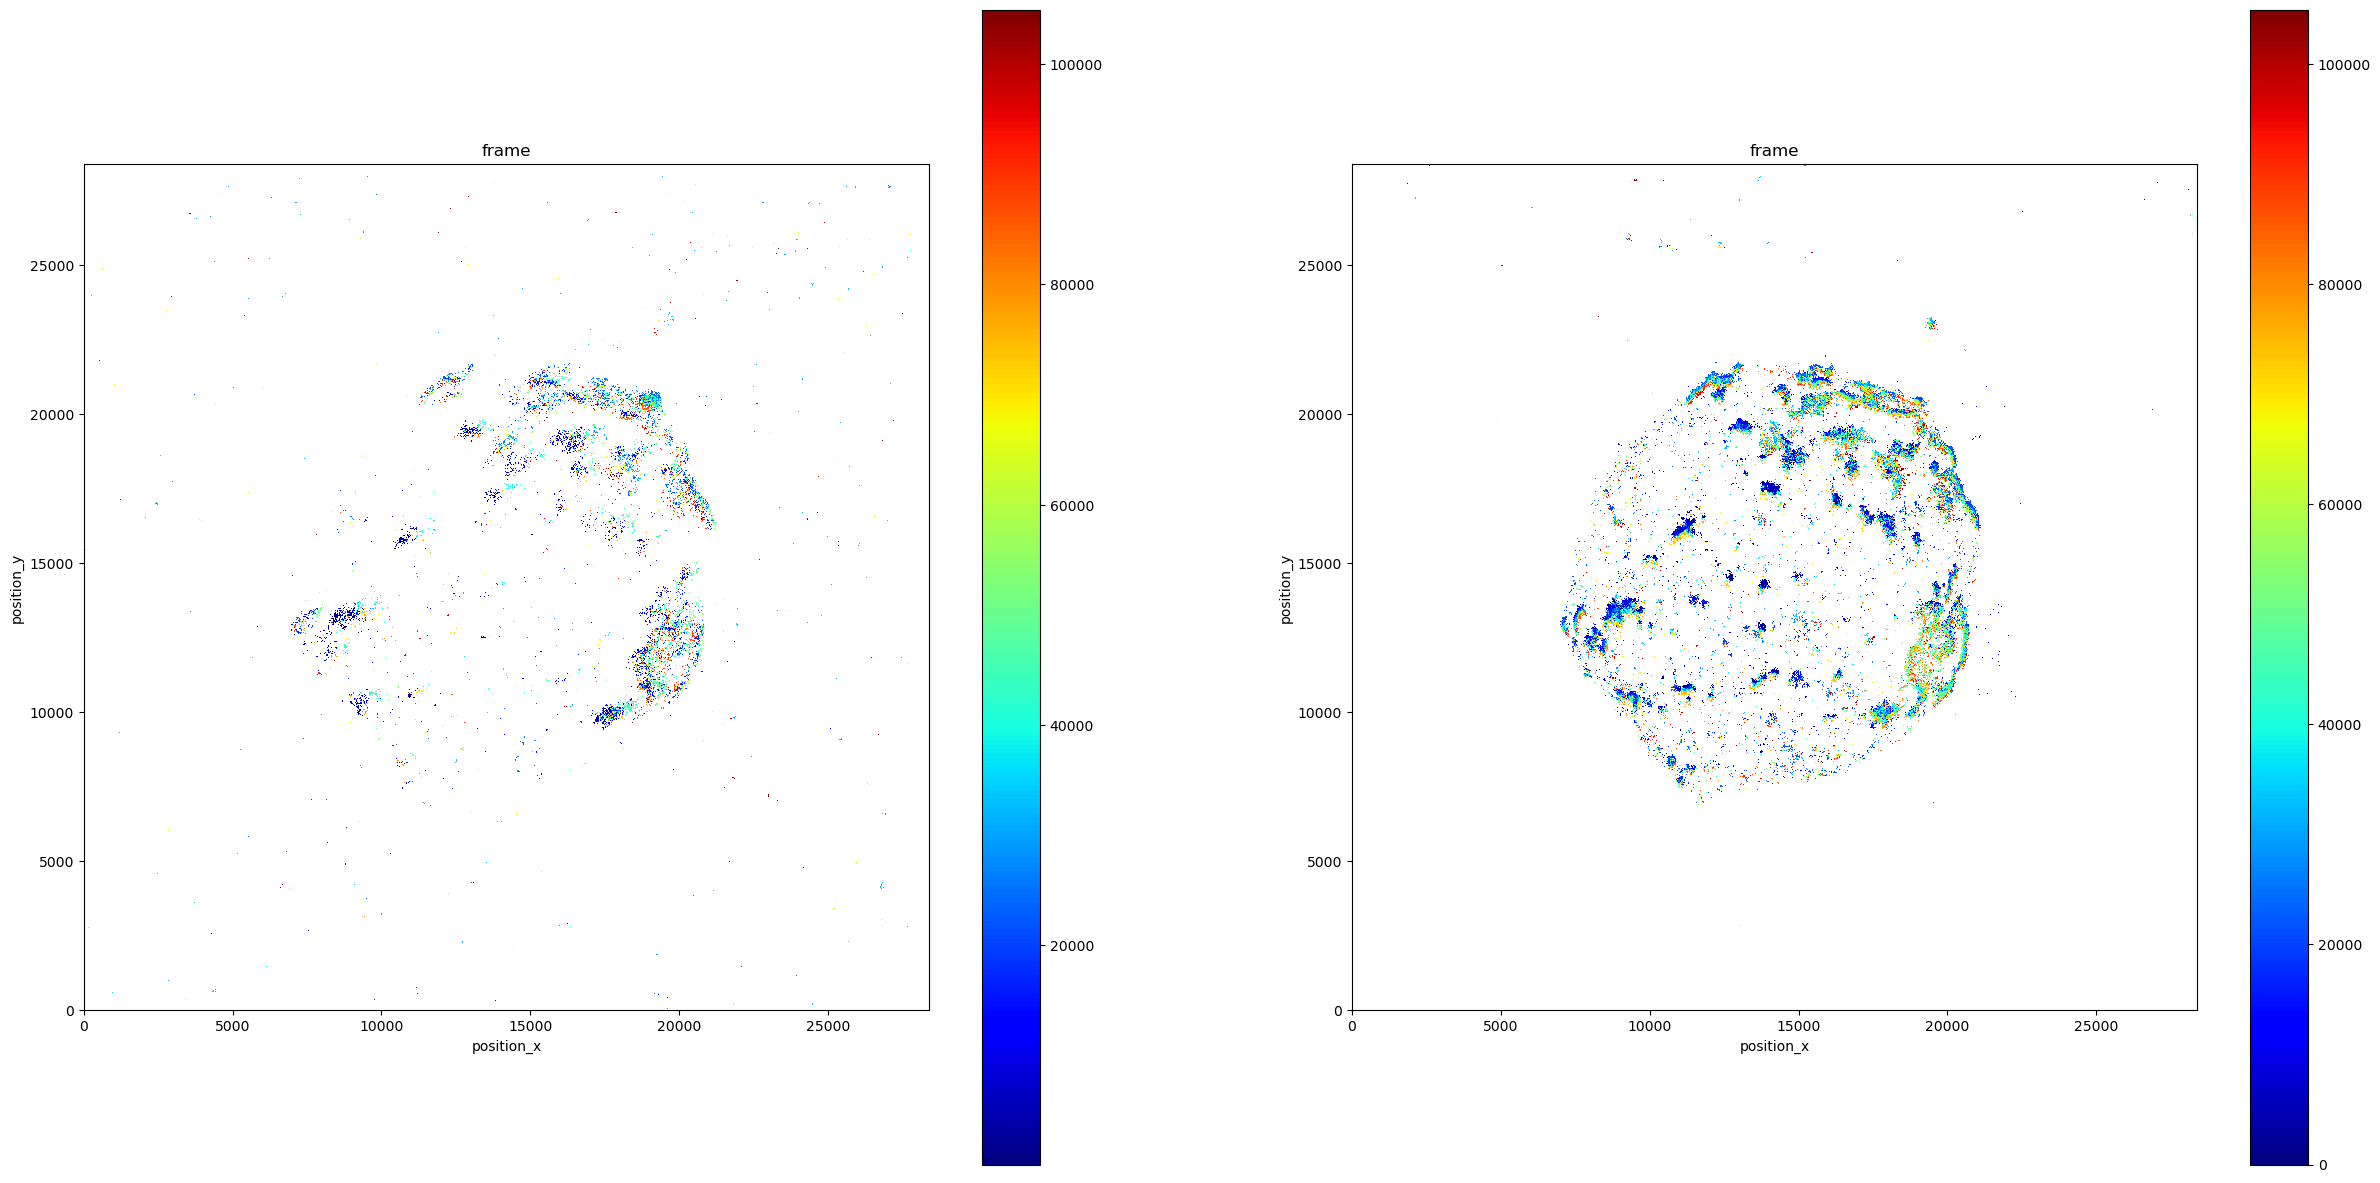

In [7]:
# plt in 2D
plt.style.use('default')
fig, axes = plt.subplots(1, 2, figsize=(30, 15))
lc.render_2d_mpl(locs_532, loc_properties=['position_x', 'position_y'], ax= axes[0], bin_size=(20, 20),  other_property='frame', cmap='jet', bin_range=(0, 28416));
lc.render_2d_mpl(locs_640, loc_properties=['position_x', 'position_y'], ax= axes[1], bin_size=(20, 20), other_property='frame', cmap = 'jet', bin_range=(0, 28416));